# Training and validation curves

Eight frozen tuned candidates, four chronological folds, selected-form population.
Errors measure reconstructed BST for both direct and baseline + correction models.
Curves use sampled fitted-tree prefixes. They diagnose behavior; they do not choose
iterations, rerun search or replace release. Generations 6–9 already influenced tuning.


Default reads pinned historical diagnostics without fitting. Set `GENERATE_NEW_DIAGNOSTICS=True` and choose an unused directory for explicit regeneration. Original provenance stays unchanged.

In [1]:
# Resolve project root before package imports. Works from root or notebooks/.
import os
import sys
from pathlib import Path

PROJECT_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
                     if (p / "pyproject.toml").is_file() and (p / "pokeml").is_dir()), None)
if PROJECT_ROOT is None:
    raise RuntimeError("Launch this notebook inside the ml_pokemon project")
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
if sys.version_info[:2] != (3, 14):
    raise RuntimeError("Select project Python 3.14.8 kernel (.pokemon)")
print(f"Project: {PROJECT_ROOT} | Python: {sys.version.split()[0]} | Kernel: {sys.executable}")


Project: /Users/pano/Library/Mobile Documents/com~apple~CloudDocs/coding/portfolio/ml_pokemon | Python: 3.14.8 | Kernel: /Users/pano/venv/pokemon/.pokemon/bin/python


In [2]:
from hashlib import sha256
import json
import pandas as pd
from IPython.display import Image, display
from pokeml.evaluation.curves import diagnose_run
from pokeml.pipeline.workflow import package_source_digest

PARENT_RUN = Path("artifacts/workflow/pokemon_tuned_60_v1")
DIAGNOSTICS_RUN = Path("artifacts/diagnostics/pokemon_tuned_60_curves_v2")
MAX_CHECKPOINTS = 200

GENERATE_NEW_DIAGNOSTICS = False
HISTORICAL_SNAPSHOT = {'summary.csv': '7c5dd18f480d556d120c954f10e88206080970a5a62e85c5d27815977166d5e5', 'manifest.json': '253883abd6857db0df30849758ddf41f4bcde7a527b61d6dc1b5459e27878ec9', 'curves.csv': 'b652fdd885d23661595fda001f82a8f2751f9575a96567c85fbbfa2e3befe4b6', 'plots/generation_8_mae.png': '7664441369bdf5d3c8c0cb2a2d52f6580190e21627a2240e62bc9c8e7471a935', 'plots/generation_9_mae.png': '8d2f6d2169870f7921dc8adb966f045ea334f70a1598abecda9387341cc1c87d', 'plots/generation_7_rmse.png': '915c941535b0c0a81ad845284942eaaedfaa864609c93c400d2967b03e325059', 'plots/generation_6_rmse.png': 'a16a1d179ed63fc14e622f5f613a29271b3e7baa5c86aea4bb9316a9893d8384', 'plots/generation_6_mae.png': '804cab4b0263310aa2f9c4a369dd30d998b59a175a6d48a08411c079cd77ed46', 'plots/generation_7_mae.png': '8ce3f454b05f8f51f3411dc4e22caf97d70cda3280f0afeec5d6c5bf4e87920f', 'plots/generation_9_rmse.png': 'e141be9e793b753c7987be1aea6fea4c6c6f2ebc8e409c456eb7f1a0979505b4', 'plots/generation_8_rmse.png': 'edfeb8607ecaf7b7eab58263c5aaa39afdbad17a7e160609dce2016e67ae0d6c'}

## Load or generate diagnostics

Earlier folds refit frozen parameters without auxiliary quantile models. Generation 9
reuses saved evaluation models. Final curve errors must reproduce parent-run scores.
Historical source fingerprints stay visible; normal workflow cache checks remain strict.
Set a new diagnostics directory to regenerate curves after changing diagnostic code.


In [3]:
parent_manifest_path = next(PARENT_RUN.glob("*_model_manifest.json"))
parent = json.loads(parent_manifest_path.read_text())
if not GENERATE_NEW_DIAGNOSTICS:
    for filename, digest in HISTORICAL_SNAPSHOT.items():
        if sha256((DIAGNOSTICS_RUN / filename).read_bytes()).hexdigest() != digest:
            raise ValueError(f"Historical diagnostic file changed: {filename}")

if DIAGNOSTICS_RUN.exists():
    if GENERATE_NEW_DIAGNOSTICS:
        raise FileExistsError("New diagnostics require an unused directory")
    provenance = json.loads((DIAGNOSTICS_RUN / "manifest.json").read_text())
    if provenance.get("status") != "complete":
        raise RuntimeError("Incomplete diagnostics. Choose new DIAGNOSTICS_RUN.")
    if provenance["source_sha256"] != package_source_digest():
        print("Historical saved curves; original diagnostic source differs from current package.")
    assert provenance["parent_manifest_sha256"] == sha256(parent_manifest_path.read_bytes()).hexdigest()
    assert provenance["maximum_checkpoints"] == MAX_CHECKPOINTS
    assert provenance["training_sha256"] == sha256(Path(parent["training_csv"]).read_bytes()).hexdigest()
else:
    if not GENERATE_NEW_DIAGNOSTICS:
        raise FileNotFoundError("Saved diagnostics missing; explicit generation requires a new directory")
    diagnose_run(PARENT_RUN, DIAGNOSTICS_RUN, MAX_CHECKPOINTS)
curves = pd.read_csv(DIAGNOSTICS_RUN / "curves.csv")
summary = pd.read_csv(DIAGNOSTICS_RUN / "summary.csv")
provenance = json.loads((DIAGNOSTICS_RUN / "manifest.json").read_text())
display(pd.Series(provenance))


Historical saved curves; original diagnostic source differs from current package.


status                                                               complete
parent_directory            /Users/pano/Library/Mobile Documents/com~apple...
packages                    {'numpy': '2.5.4', 'pandas': '3.0.6', 'scikit-...
parent_manifest_sha256      277c6a8790be771bae02c7b0d10daed3e8b15edf17ecd1...
parent_source_sha256        82be212780ebd6d6f93a99492b7a76d03946c99e32734b...
source_sha256               1d52ca1bbe5b9b3864d90a54b2a9aa40f04c46d16b8c81...
training_sha256             2c6785a018140d20ce85b349fa1c244bdadf4c03eccb54...
parameters                  {'direct_cat_native': {'cat_features': None, '...
validation_generations                                           [6, 7, 8, 9]
maximum_checkpoints                                                       200
population                                                     selected_forms
early_stopping                                                          False
note                        Frozen tuned parameters; sampled pre

## MAE curves

Blue: training rows evaluated with fitted inference-time preprocessing.
Orange: forward validation generation. Dashed lines: fitted stage/rarity baseline.
Small gaps do not prove generalisation; large gaps can reflect overfitting or generation shift.


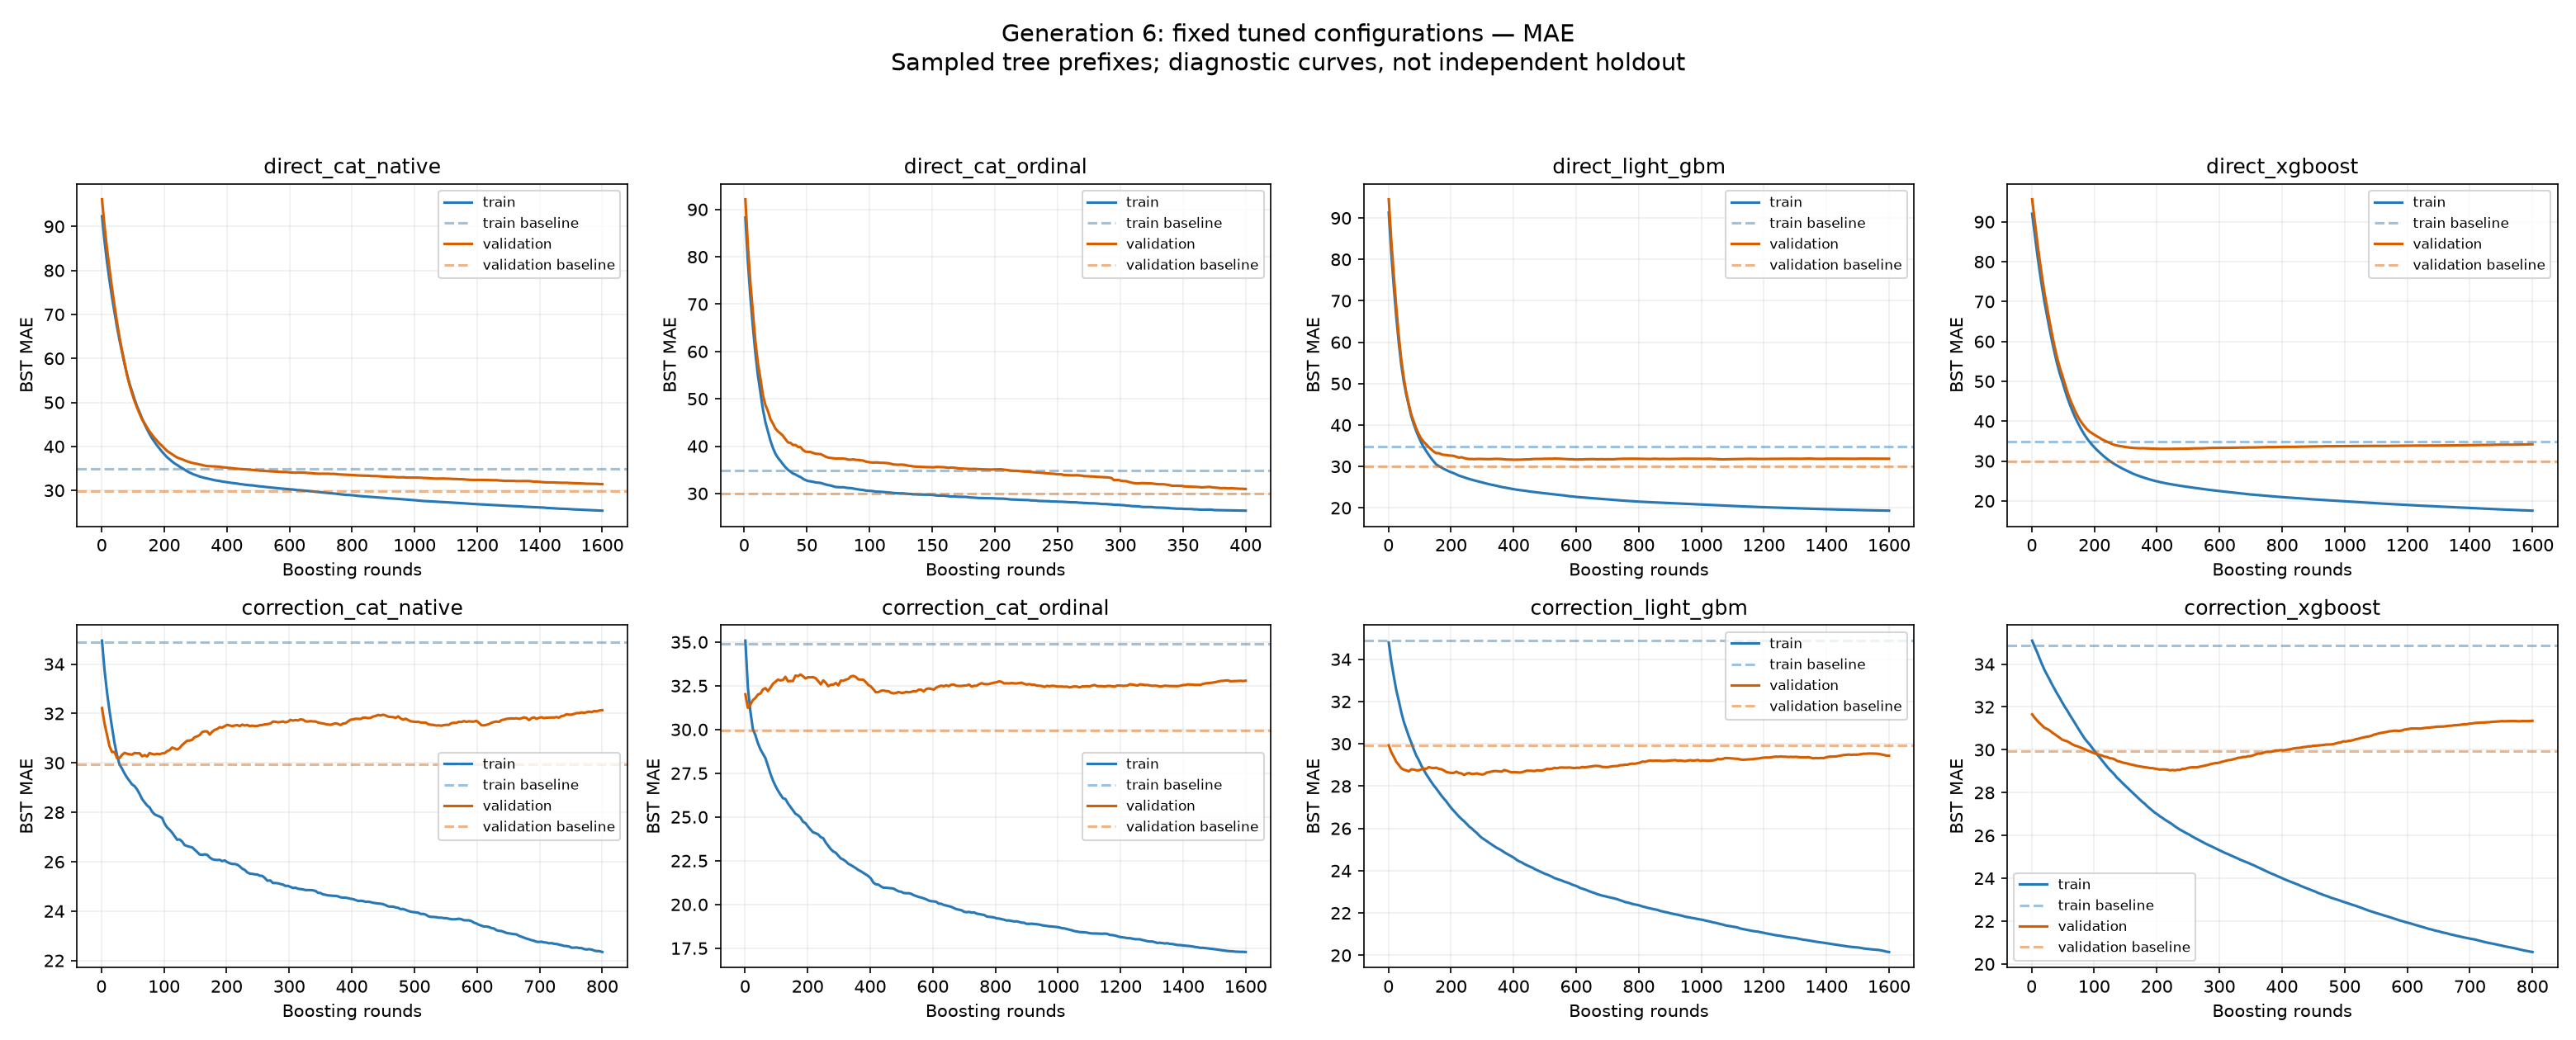

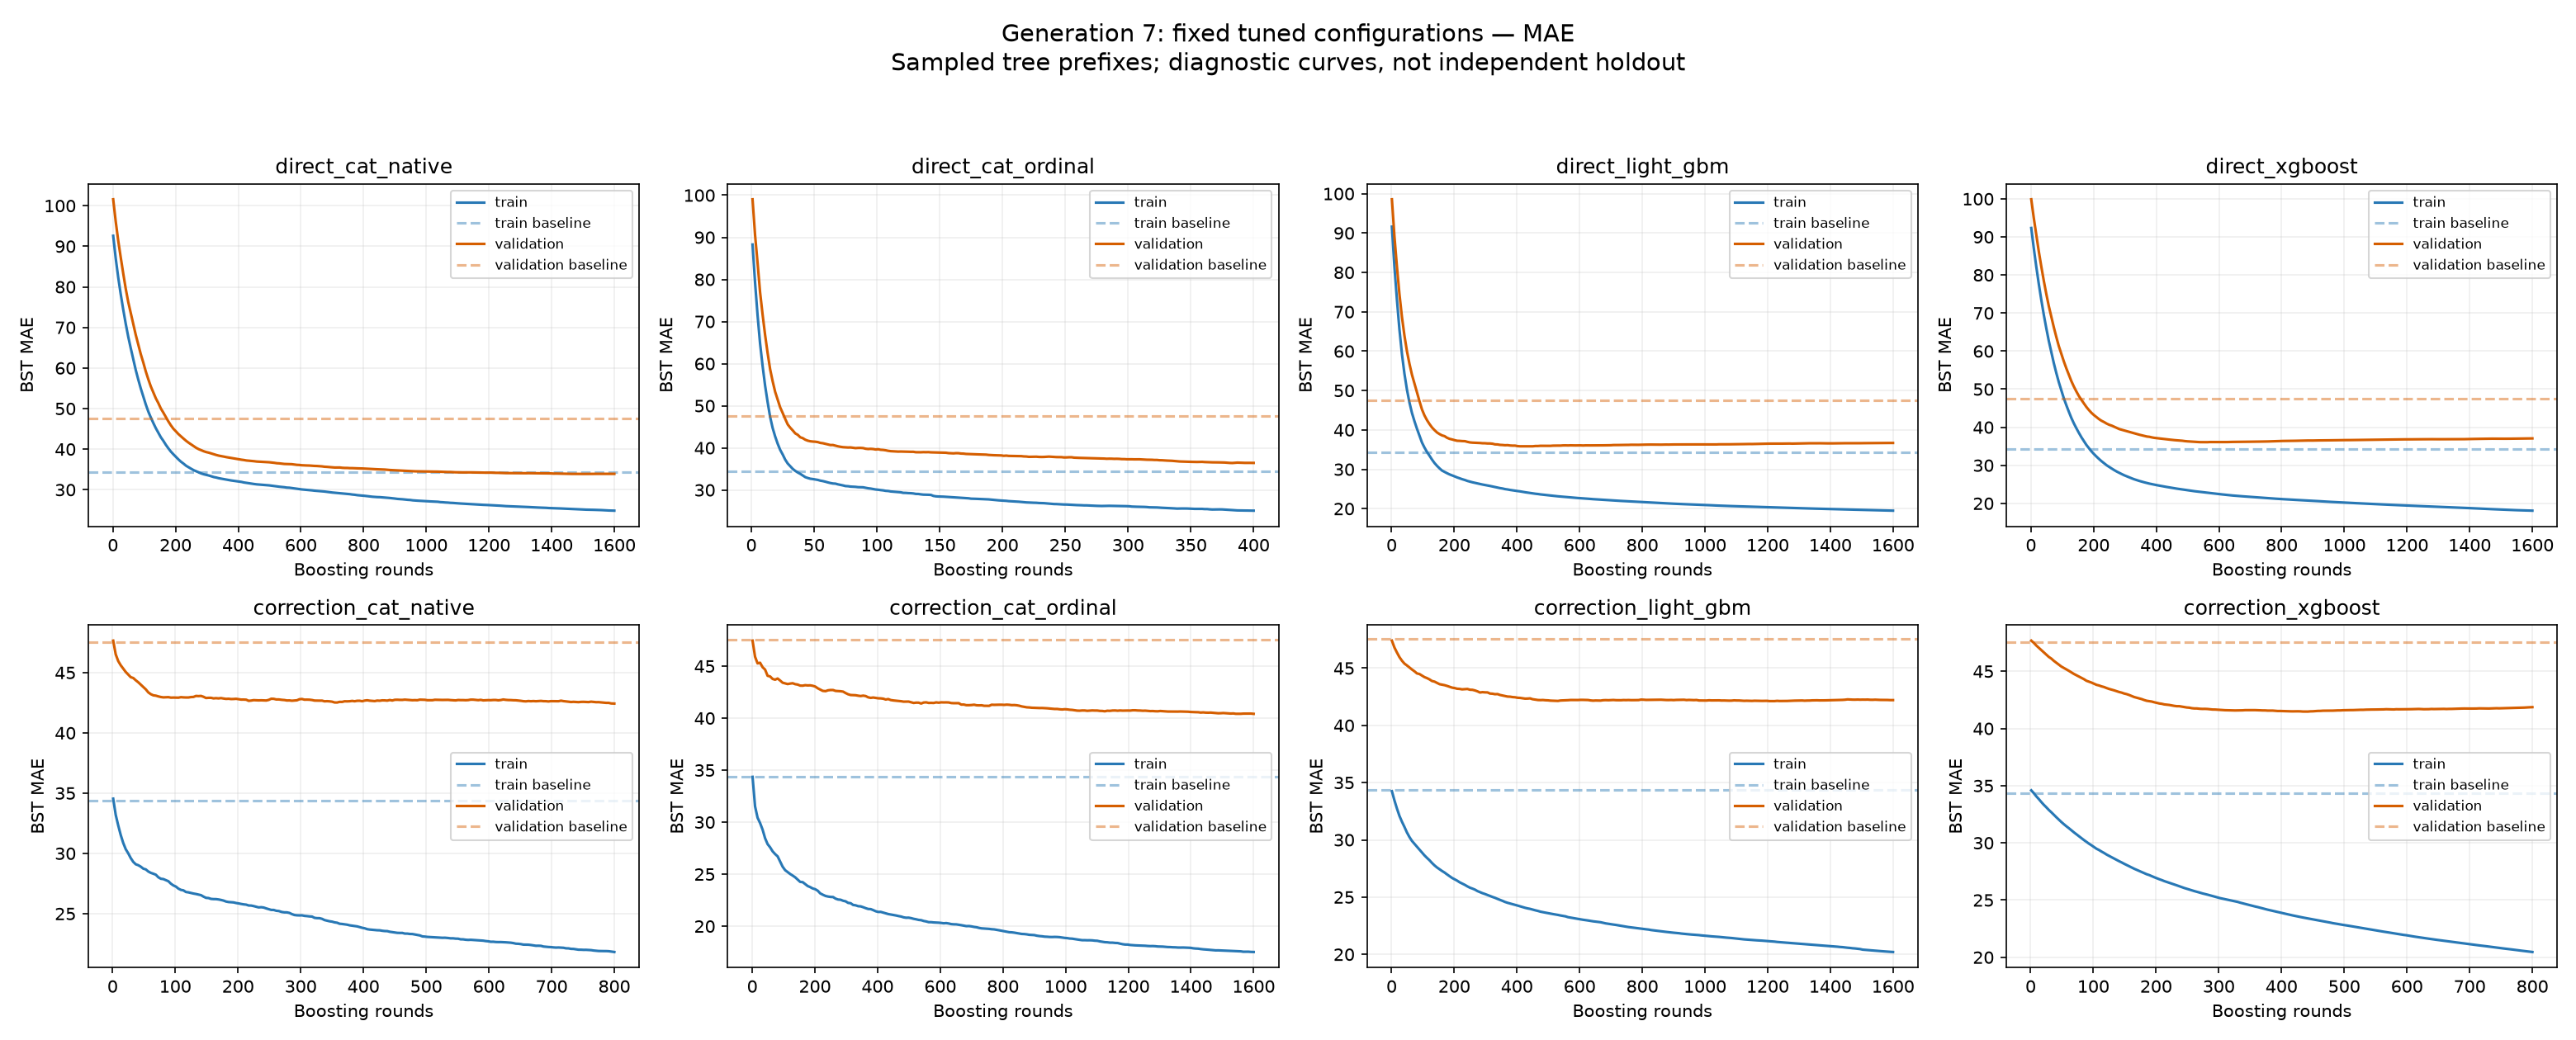

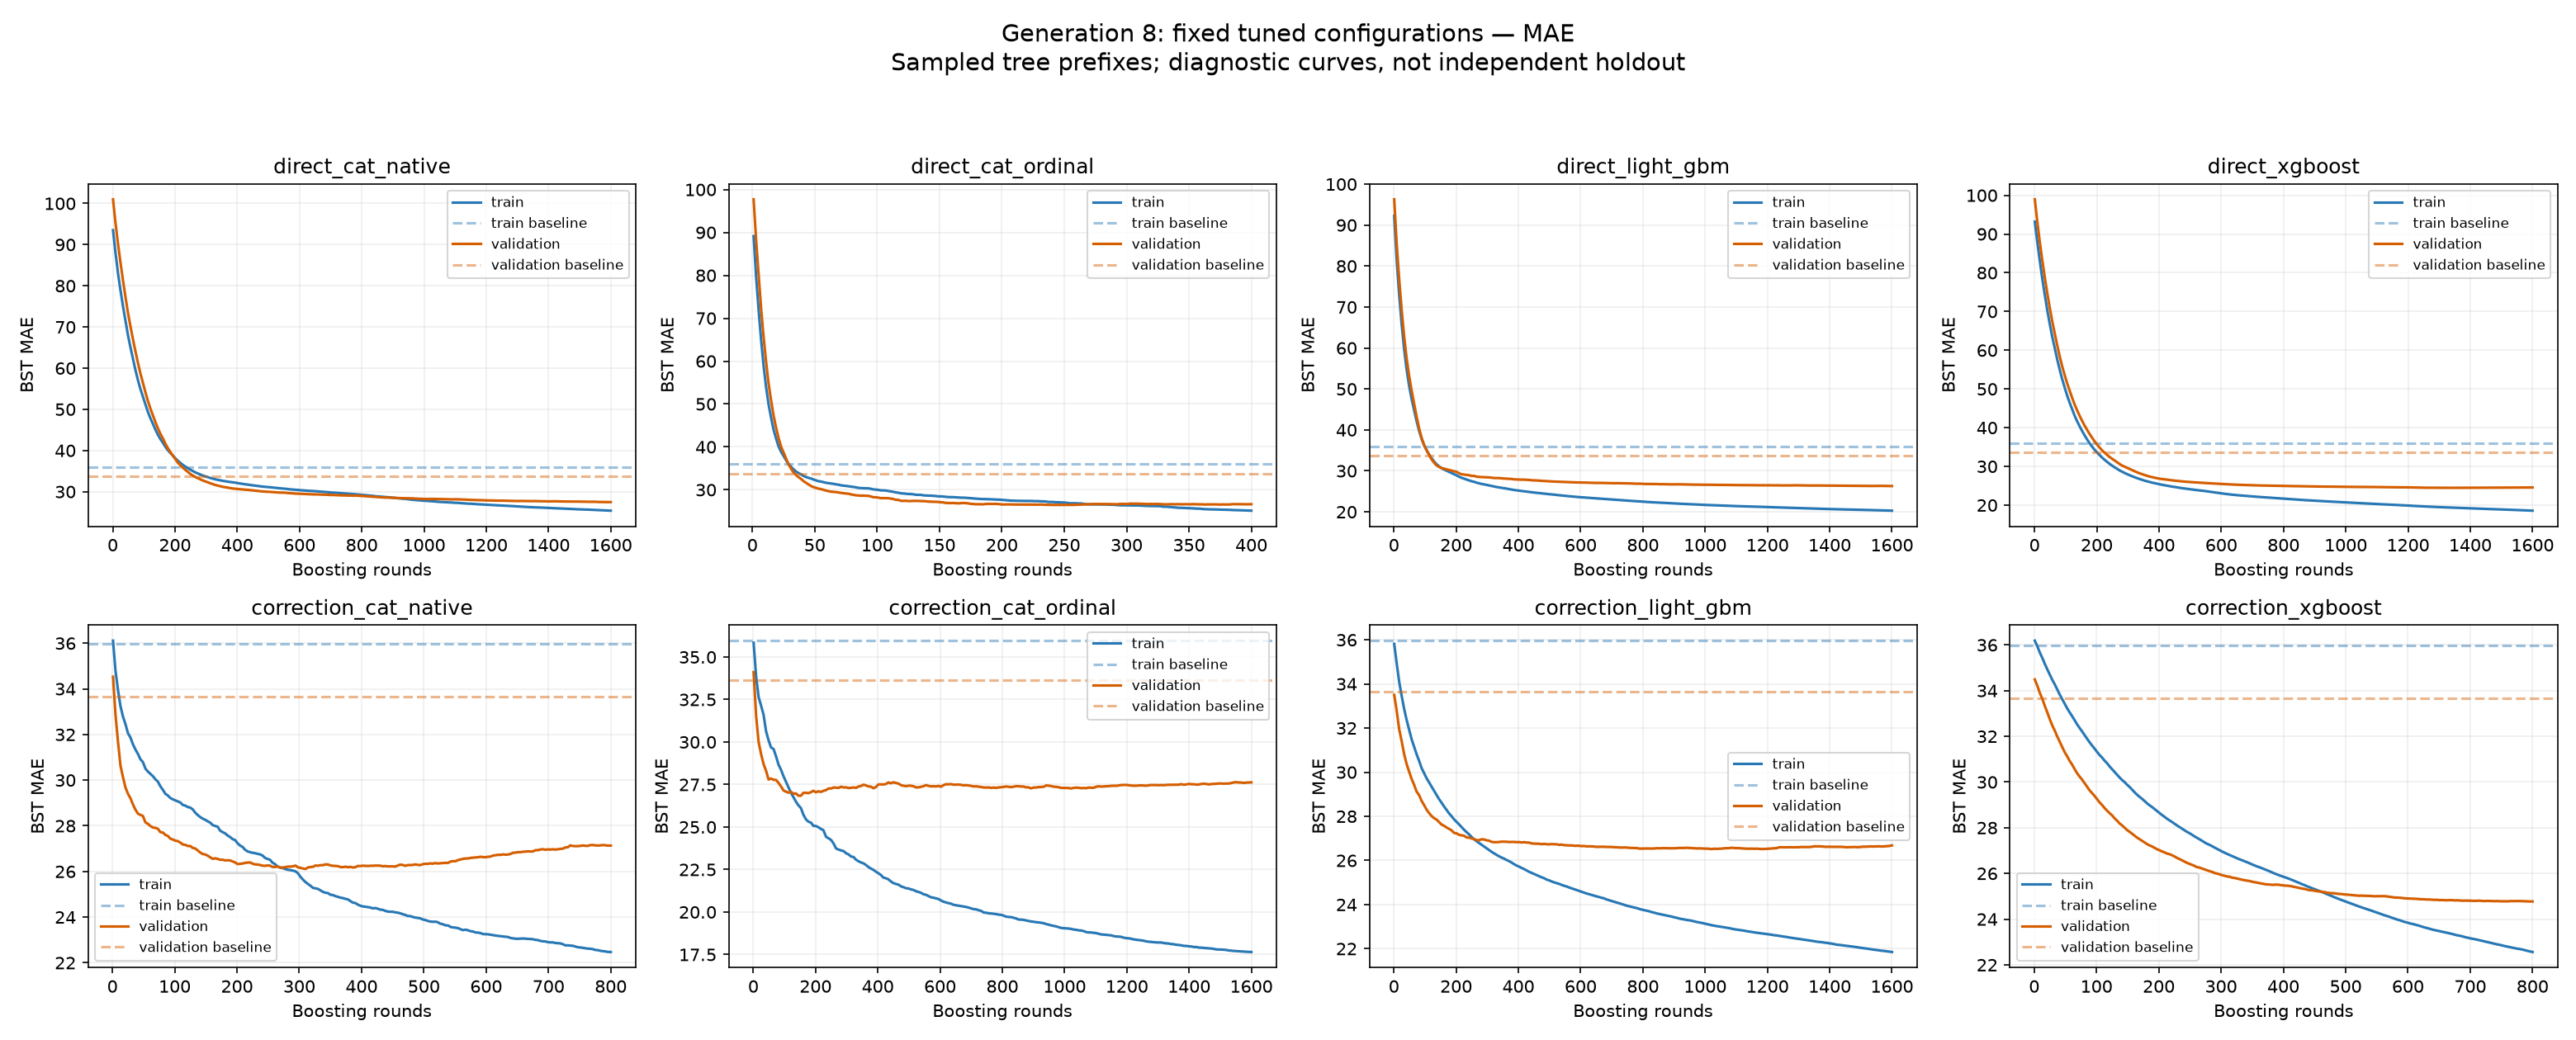

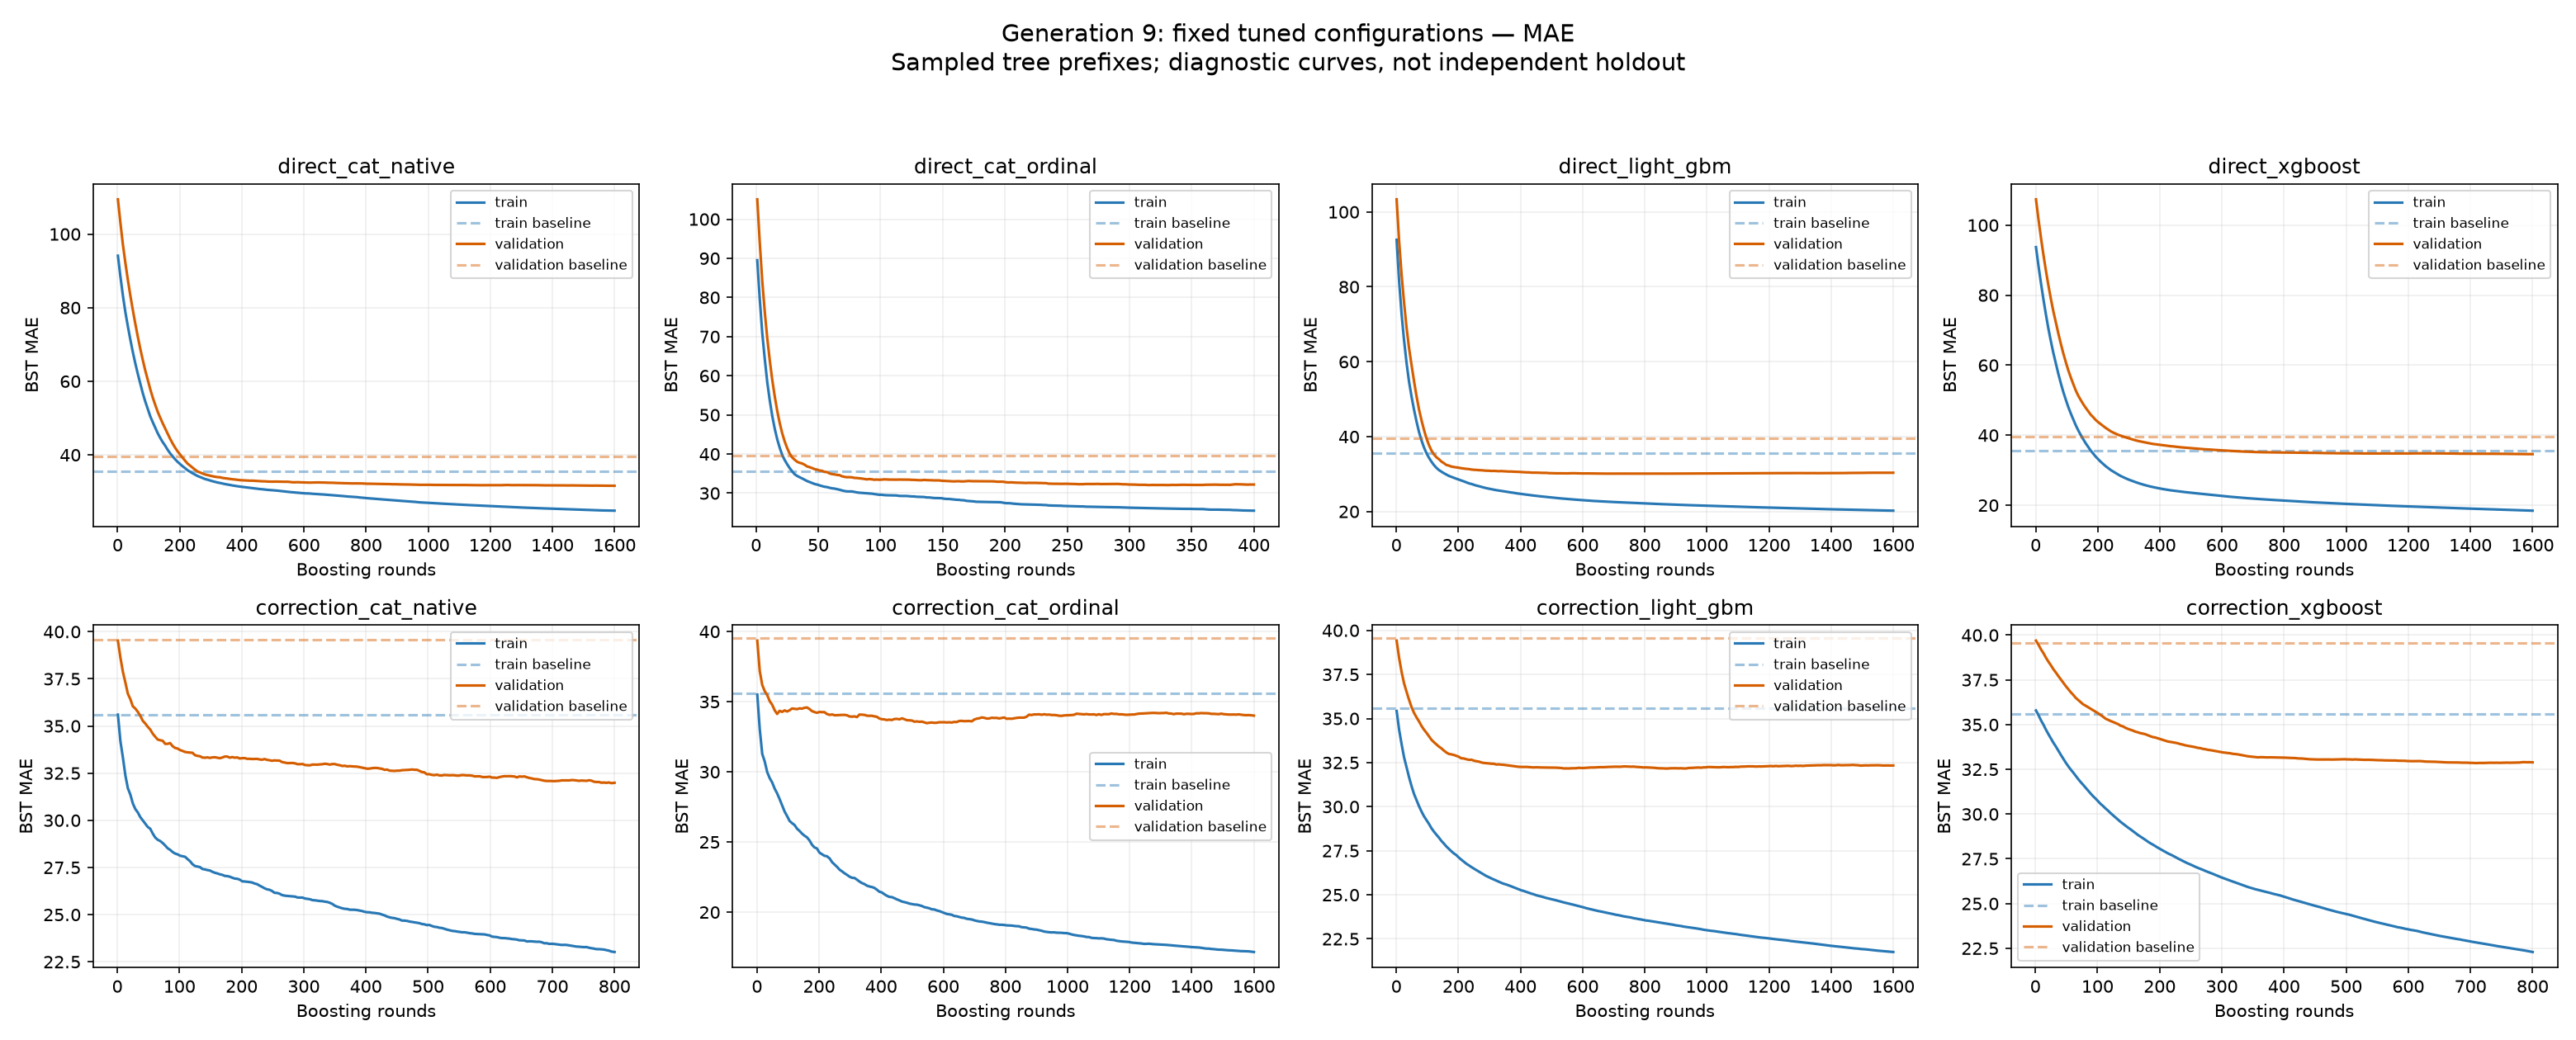

In [4]:
for generation in provenance["validation_generations"]:
    display(Image(filename=str(DIAGNOSTICS_RUN / f"plots/generation_{generation}_mae.png")))


## RMSE curves

RMSE highlights large misses. Panels use each candidate's actual fitted tree count.
Final round remains selected configuration; curves trigger no early stopping.


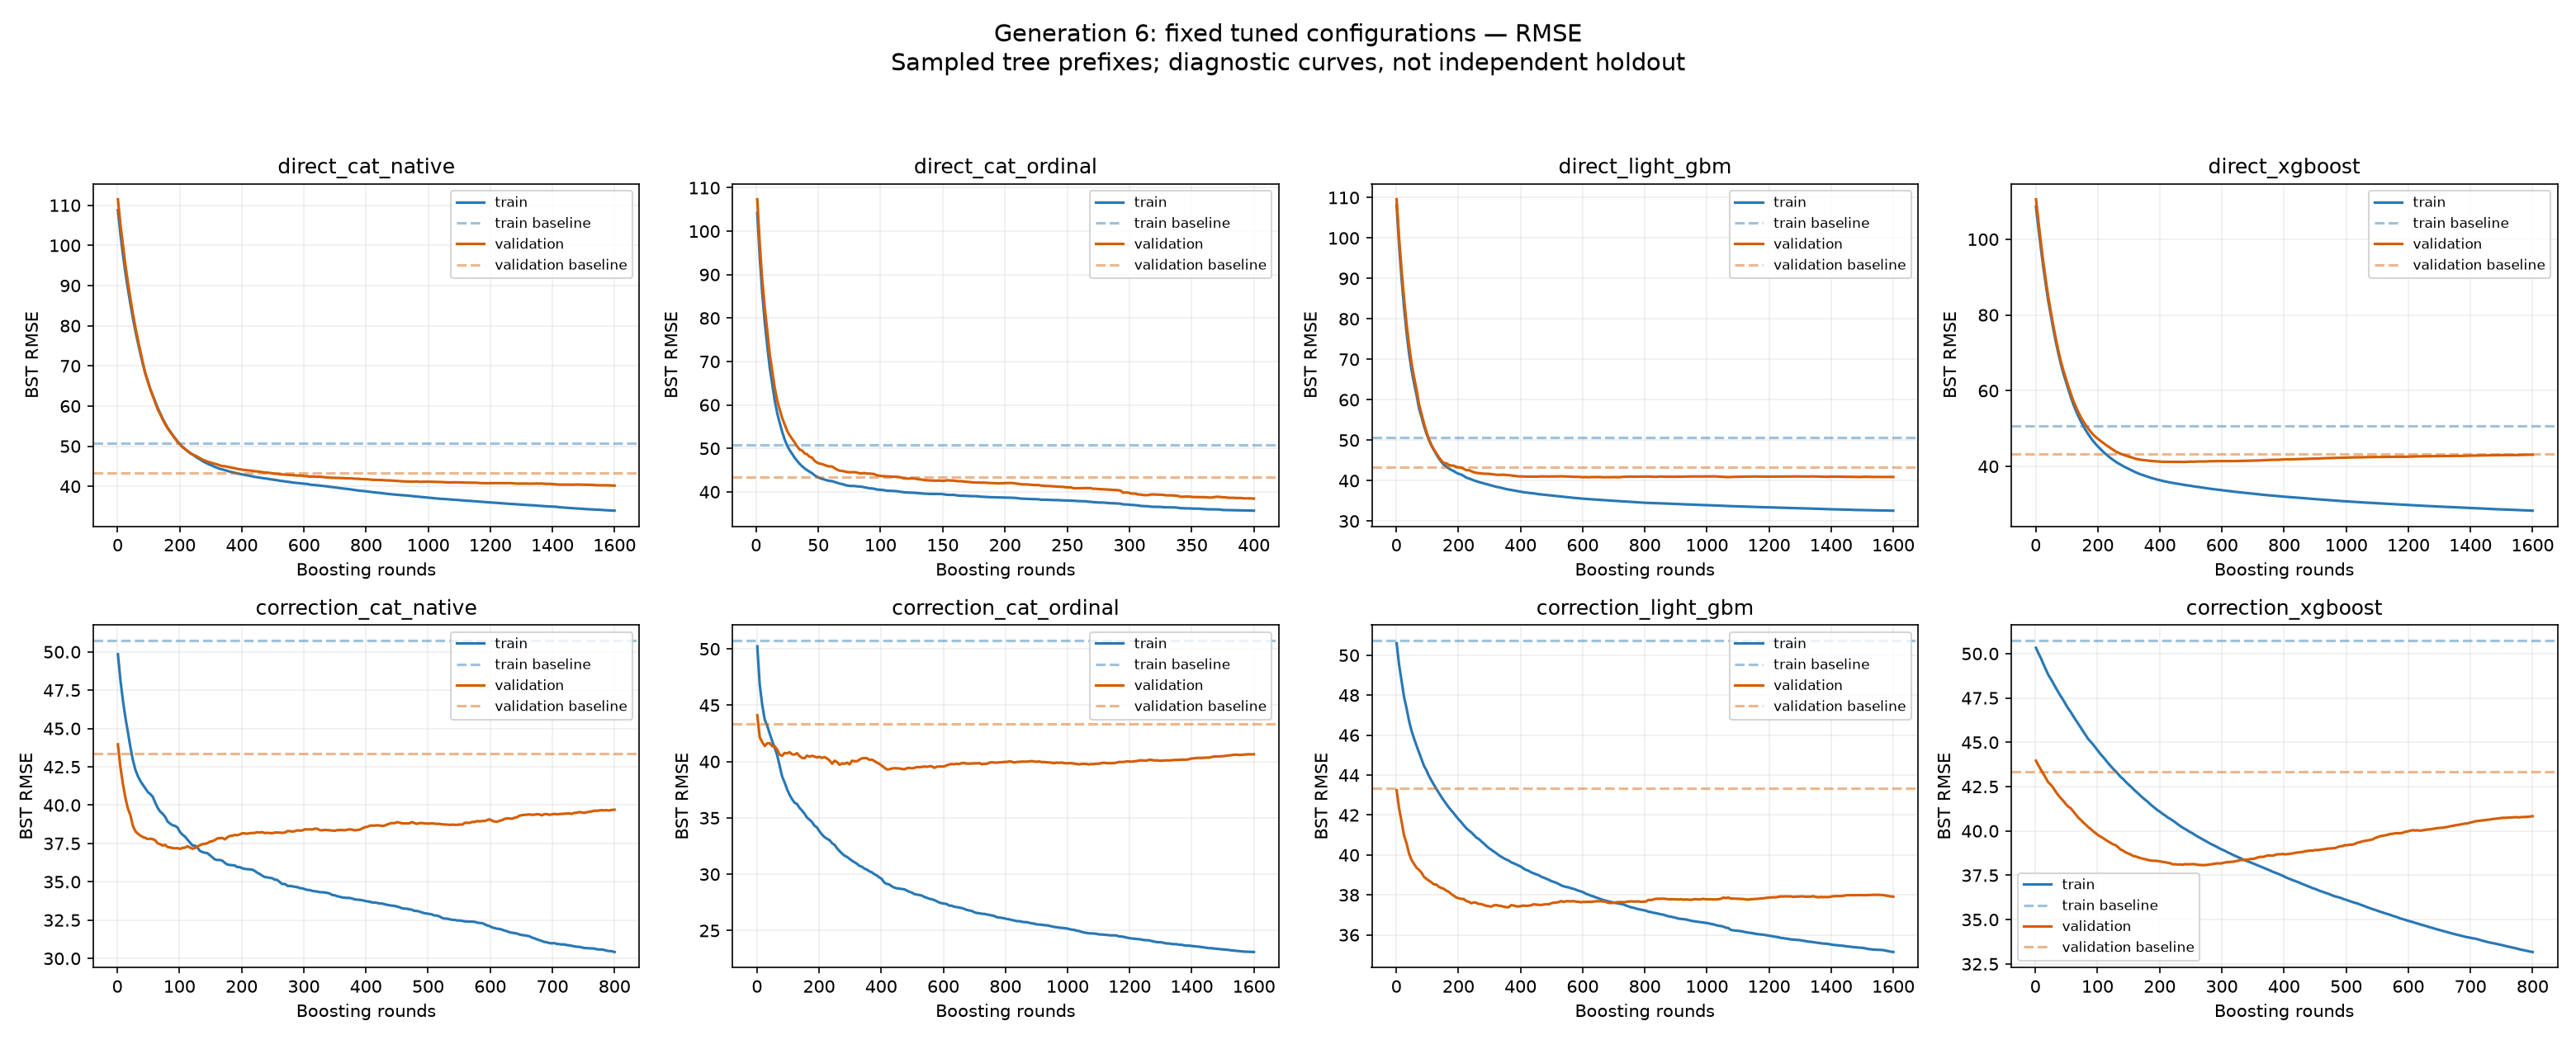

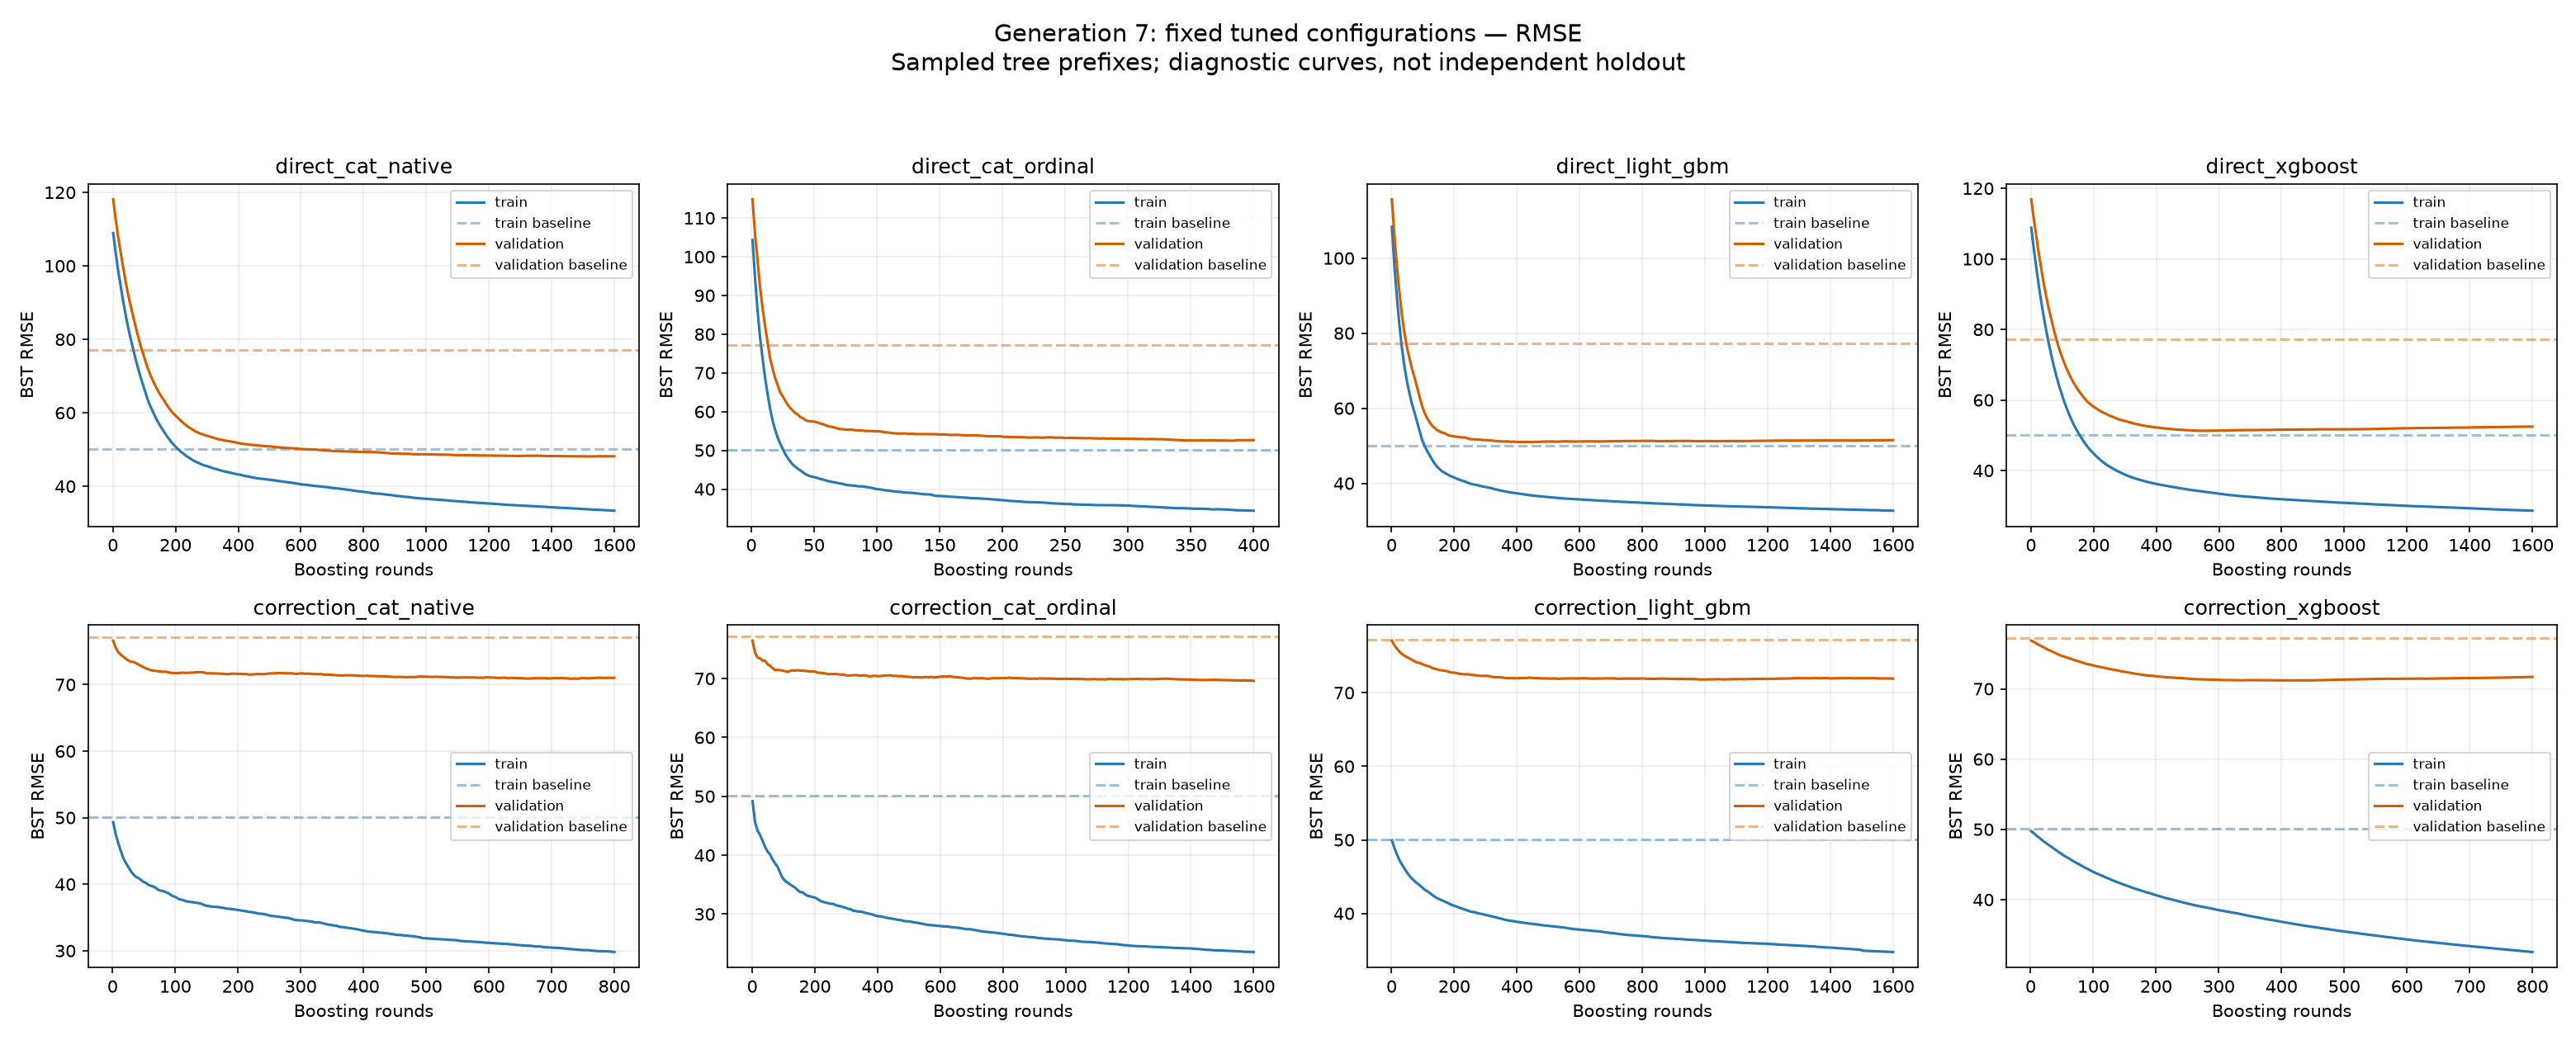

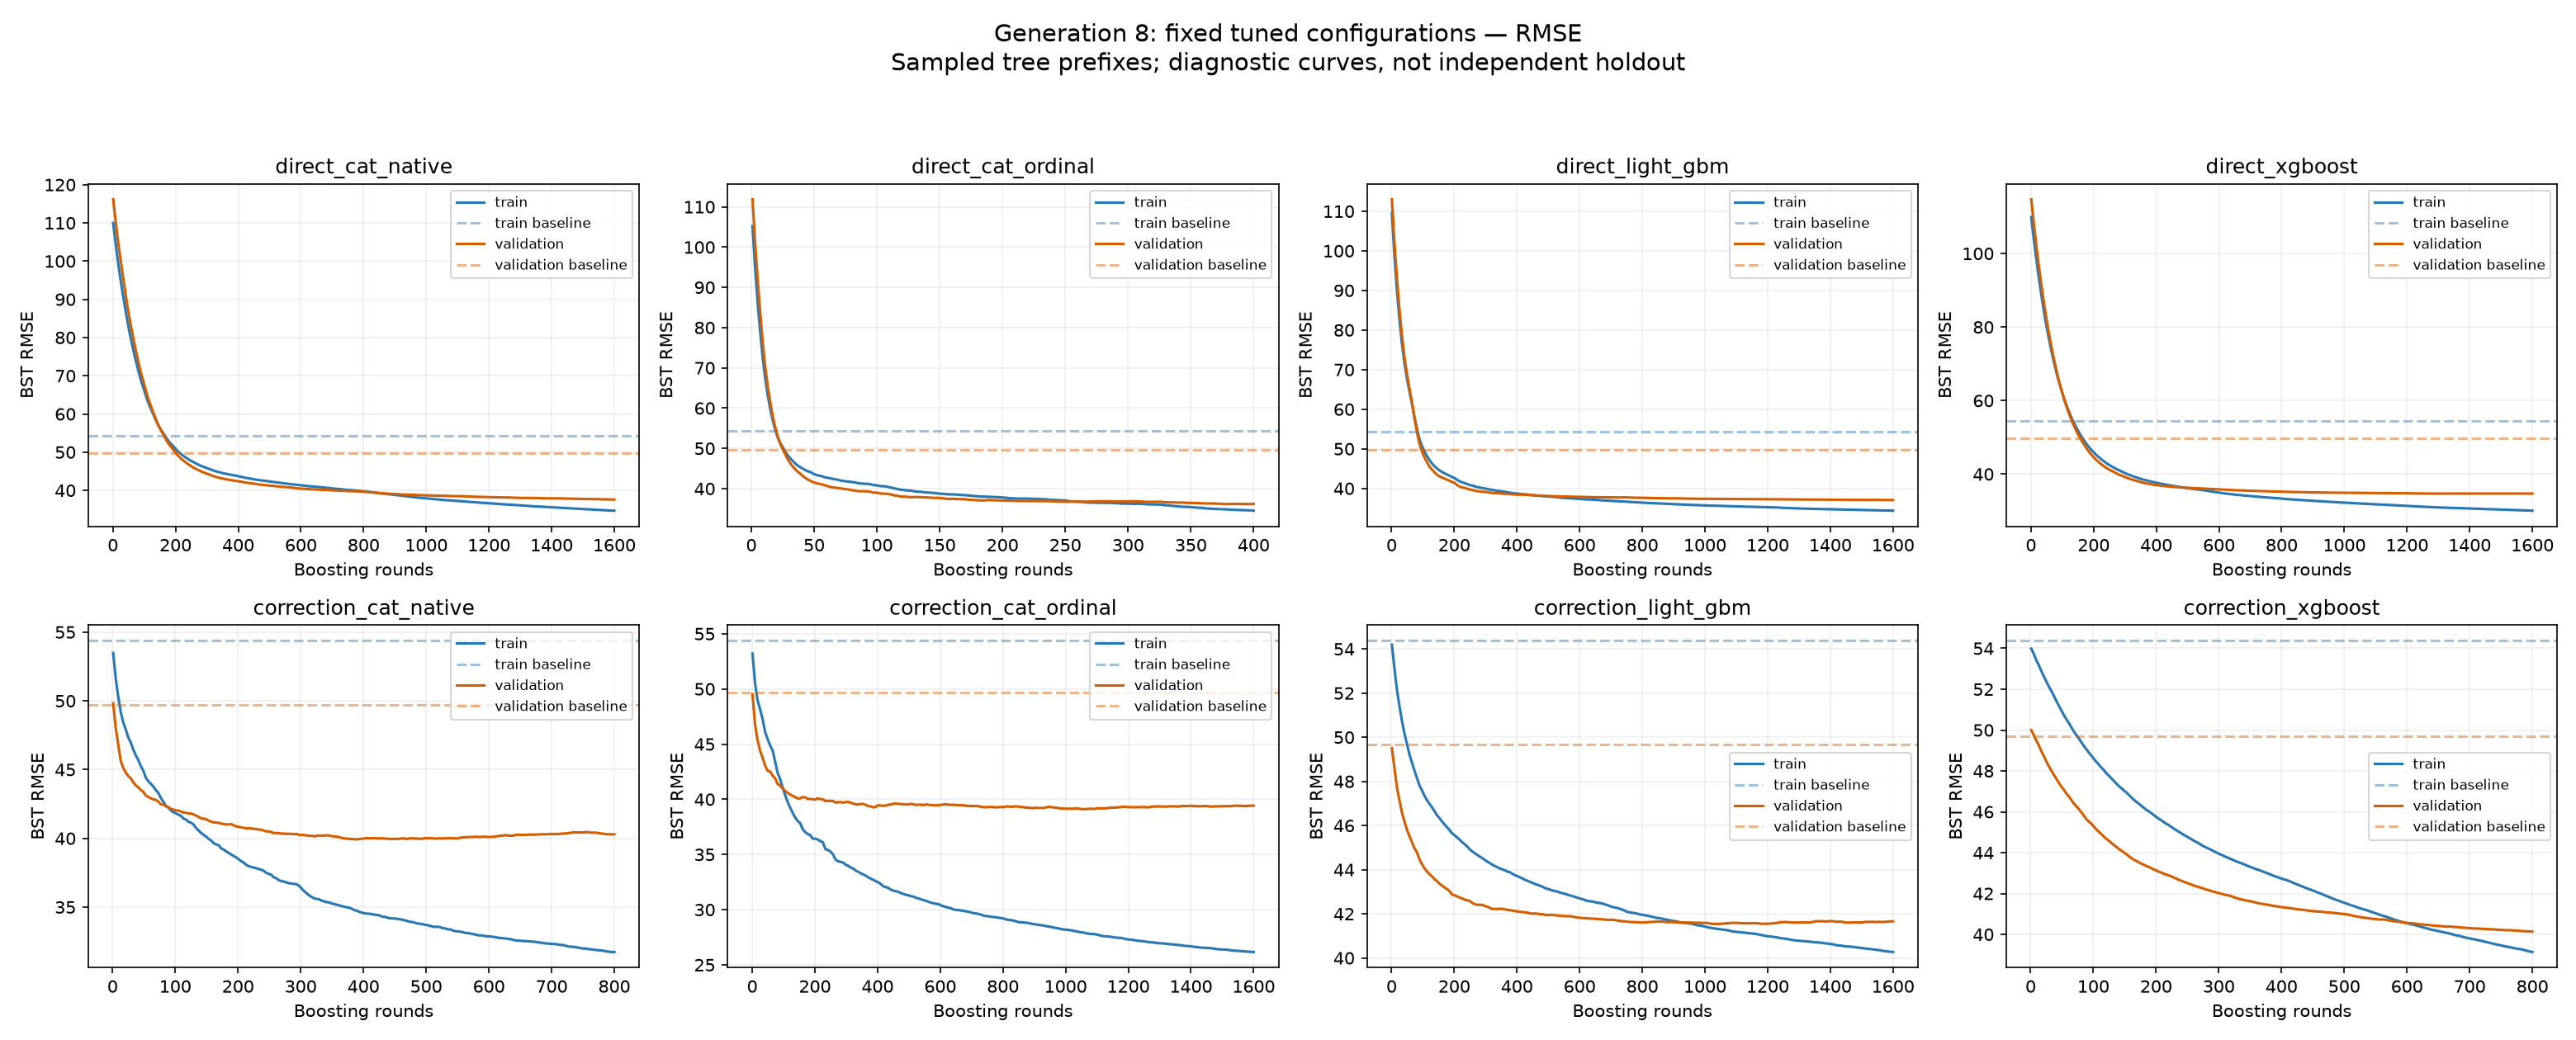

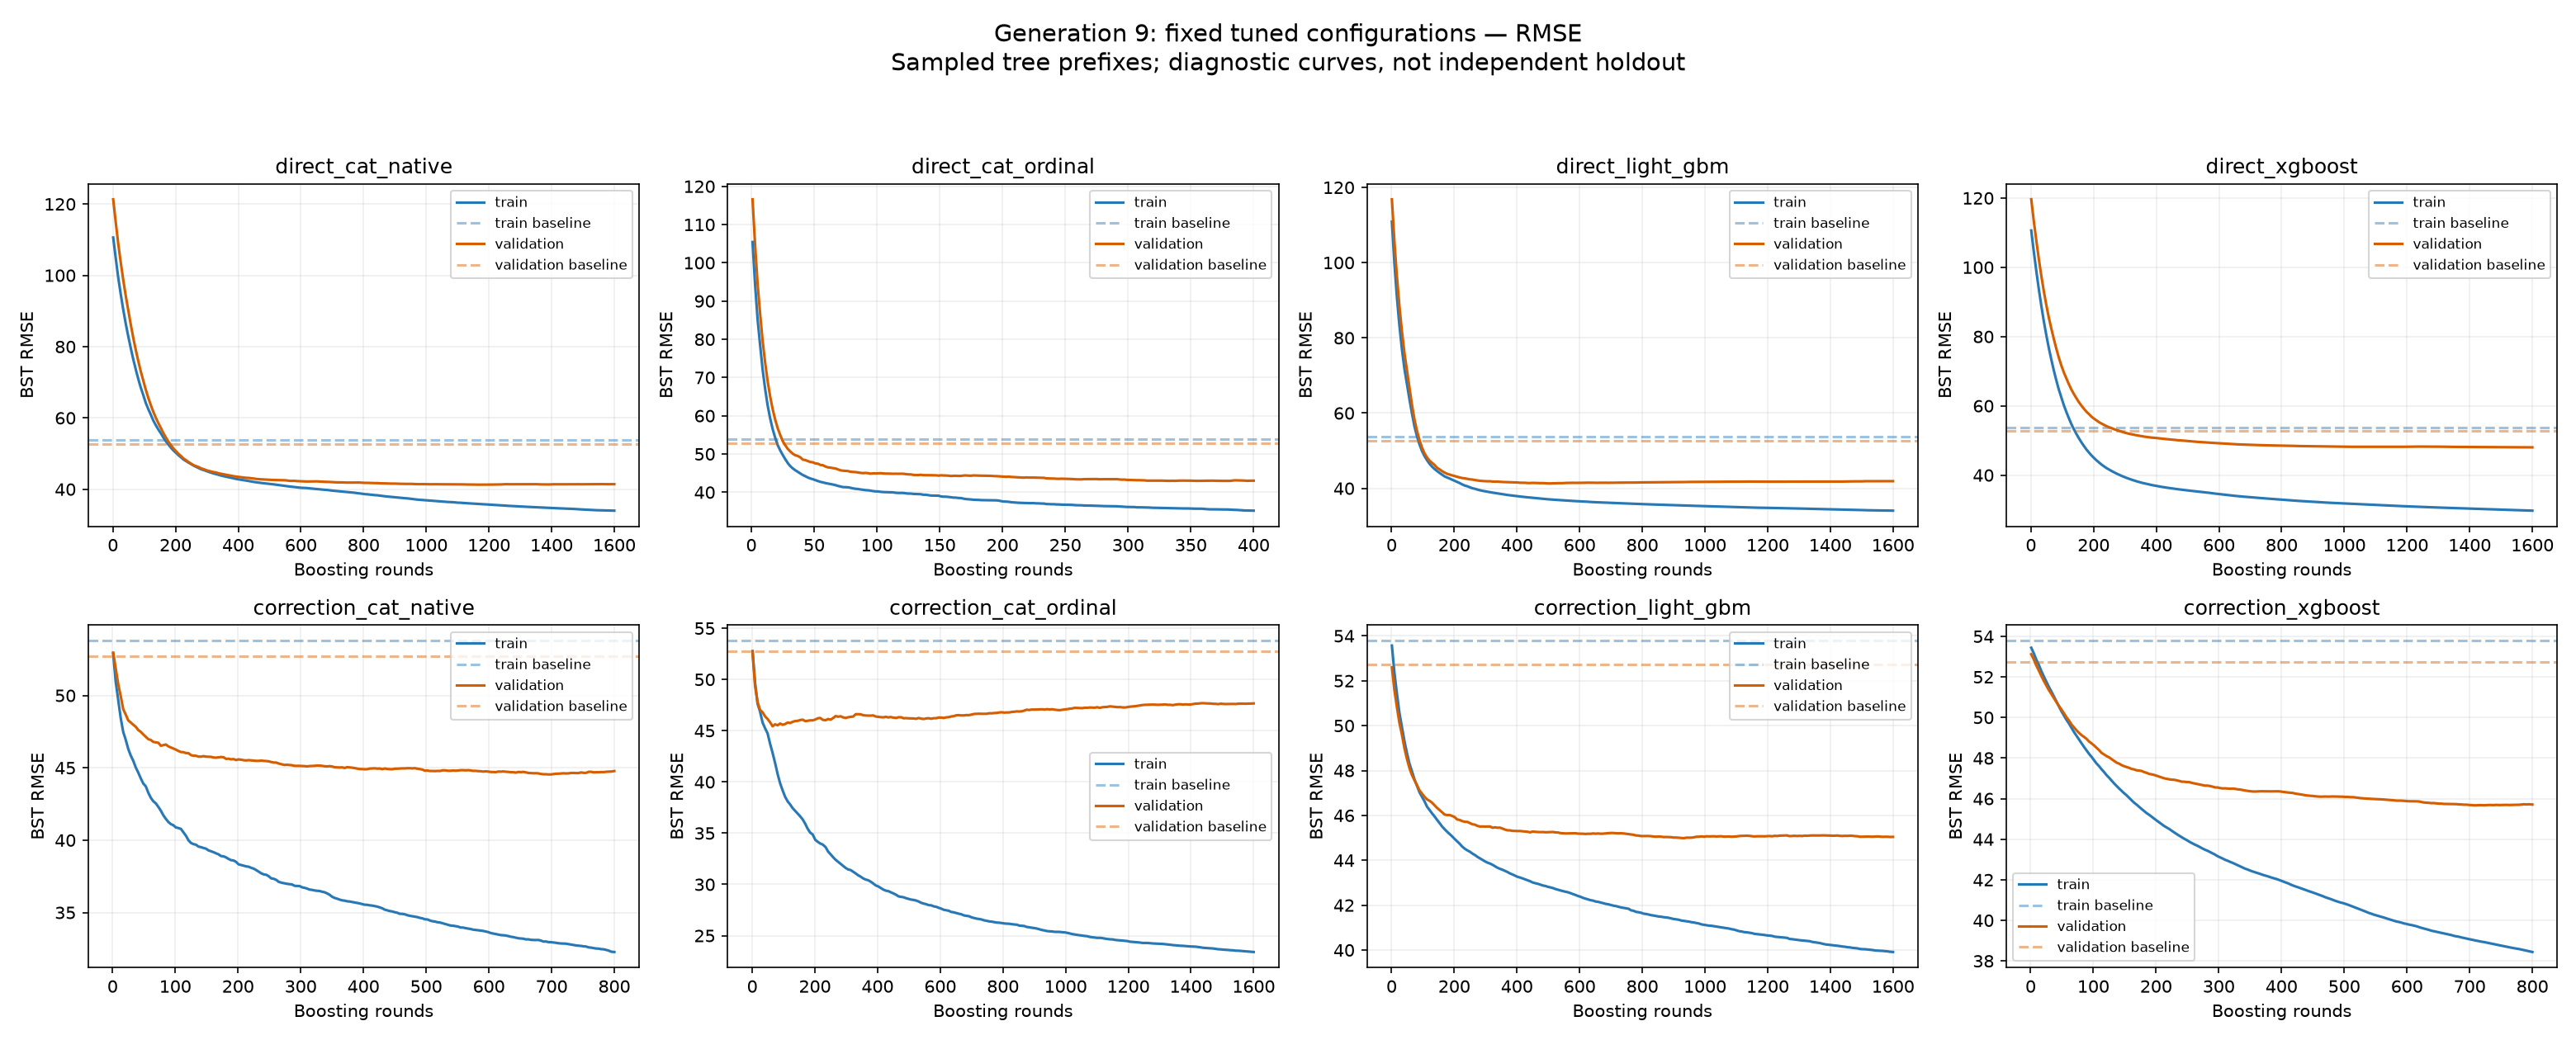

In [5]:
for generation in provenance["validation_generations"]:
    display(Image(filename=str(DIAGNOSTICS_RUN / f"plots/generation_{generation}_rmse.png")))


## Gaps and validation deterioration

Minimum round is lowest error among sampled checkpoints, not optimal early-stopping
recommendation. Positive validation deterioration alongside falling training error
is an overfitting signal. Do not use these explored generations as independent tests.


In [6]:
display(summary[["model", "generation", "fitted_rounds", "final_train_MAE", "final_validation_MAE", "MAE_gap", "min_MAE_round", "MAE_deterioration", "train_MAE_change_after_min"]].round(3))
display(summary.sort_values("RMSE_deterioration", ascending=False).head(12).round(3))
assert set(curves.generation) == {6, 7, 8, 9}
assert curves.model.nunique() == 8
assert not curves.duplicated(["model", "generation", "split", "iteration"]).any()
print("CLI: python -m pokeml.cli model training-curves --run-directory", PARENT_RUN,
      "--output-directory artifacts/diagnostics/my_unique_curves")


,model,generation,fitted_rounds,final_train_MAE,final_validation_MAE,MAE_gap,min_MAE_round,MAE_deterioration,train_MAE_change_after_min
0,direct_cat_native,6,1600,25.395,31.425,6.030,1600,0.000,0.000
1,direct_cat_ordinal,6,400,26.367,30.943,4.577,400,0.000,0.000
2,direct_light_gbm,6,1600,19.323,31.859,12.536,402,0.238,-5.181
3,direct_xgboost,6,1600,17.558,34.202,16.645,434,1.157,-6.776
4,correction_cat_native,6,800,22.343,32.133,9.789,25,1.937,-7.962
5,correction_cat_ordinal,6,1600,17.283,32.787,15.503,9,1.549,-15.104
6,correction_light_gbm,6,1600,20.153,29.435,9.282,242,0.908,-6.180
7,correction_xgboost,6,800,20.559,31.353,10.794,221,2.313,-6.035
8,direct_cat_native,7,1600,24.840,33.912,9.072,1511,0.023,-0.249
9,direct_cat_ordinal,7,400,25.089,36.426,11.338,383,0.021,-0.140


,model,generation,fitted_rounds,checkpoints,train_rows,validation_rows,final_train_MAE,final_validation_MAE,MAE_gap,min_validation_MAE,min_MAE_round,MAE_deterioration,train_MAE_change_after_min,final_train_RMSE,final_validation_RMSE,RMSE_gap,min_validation_RMSE,min_RMSE_round,RMSE_deterioration,train_RMSE_change_after_min
7,correction_xgboost,6,800,200,649,72,20.559,31.353,10.794,29.040,221,2.313,-6.035,33.174,40.831,7.658,38.075,270,2.757,-6.335
4,correction_cat_native,6,800,200,649,72,22.343,32.133,9.789,30.195,25,1.937,-7.962,30.419,39.702,9.284,37.149,101,2.553,-7.814
29,correction_cat_ordinal,9,1600,200,960,122,17.161,34.006,16.845,33.469,547,0.537,-3.160,23.402,47.662,24.260,45.432,65,2.230,-19.429
3,direct_xgboost,6,1600,200,649,72,17.558,34.202,16.645,33.045,434,1.157,-6.776,28.301,43.091,14.790,41.169,475,1.922,-6.851
5,correction_cat_ordinal,6,1600,200,649,72,17.283,32.787,15.503,31.238,9,1.549,-15.104,23.096,40.644,17.548,39.304,418,1.341,-6.046
11,direct_xgboost,7,1600,200,721,106,18.083,37.066,18.983,36.076,563,0.990,-4.715,28.620,52.447,23.827,51.266,547,1.182,-5.444
26,direct_light_gbm,9,1600,200,960,122,20.226,30.355,10.129,30.086,708,0.269,-2.276,34.059,41.902,7.843,41.295,507,0.607,-2.990
6,correction_light_gbm,6,1600,200,649,72,20.153,29.435,9.282,28.527,242,0.908,-6.180,35.144,37.914,2.770,37.386,362,0.528,-4.577
15,correction_xgboost,7,800,200,721,106,20.461,41.864,21.403,41.476,438,0.388,-2.976,32.540,71.695,39.155,71.182,438,0.513,-3.731
10,direct_light_gbm,7,1600,200,721,106,19.493,36.690,17.197,35.816,426,0.874,-4.677,32.708,51.487,18.779,50.986,450,0.501,-4.031


CLI: python -m pokeml.cli model training-curves --run-directory artifacts/workflow/pokemon_tuned_60_v1 --output-directory artifacts/diagnostics/my_unique_curves
